<a href="https://colab.research.google.com/github/3B232095/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow 版本：", tf.__version__)
print("GPU 裝置：", tf.config.list_physical_devices('GPU'))


TensorFlow 版本： 2.21.0
GPU 裝置： []


In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import to_categorical

# 載入 Fashion-MNIST 資料集
fashion_mnist = keras.datasets.fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# 設定 Fashion-MNIST 類別名稱
class_names = [
    "T-shirt/top（T恤／上衣）",
    "Trouser（褲子）",
    "Pullover（套頭毛衣）",
    "Dress（洋裝）",
    "Coat（外套）",
    "Sandal（涼鞋）",
    "Shirt（襯衫）",
    "Sneaker（運動鞋）",
    "Bag（包包）",
    "Ankle boot（短靴）"
]

# 顯示資料形狀
print("訓練圖片形狀：", x_train.shape)
print("訓練標籤形狀：", y_train.shape)
print("測試圖片形狀：", x_test.shape)
print("測試標籤形狀：", y_test.shape)

# 正規化，將像素值從 0～255 轉換為 0～1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("正規化後訓練資料最小值：", x_train.min())
print("正規化後訓練資料最大值：", x_train.max())

# 將整數標籤轉成 One-Hot Encoding
y_train_onehot = to_categorical(y_train, num_classes=10)
y_test_onehot = to_categorical(y_test, num_classes=10)

print("One-Hot 訓練標籤 shape：", y_train_onehot.shape)
print("One-Hot 測試標籤 shape：", y_test_onehot.shape)

訓練圖片形狀： (60000, 28, 28)
訓練標籤形狀： (60000,)
測試圖片形狀： (10000, 28, 28)
測試標籤形狀： (10000,)
正規化後訓練資料最小值： 0.0
正規化後訓練資料最大值： 1.0
One-Hot 訓練標籤 shape： (60000, 10)
One-Hot 測試標籤 shape： (10000, 10)


/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 30701 (\N{CJK UNIFIED IDEOGRAPH-77ED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 65295 (\N{FULLWIDTH SOLIDUS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/2926353357.py:7: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s)

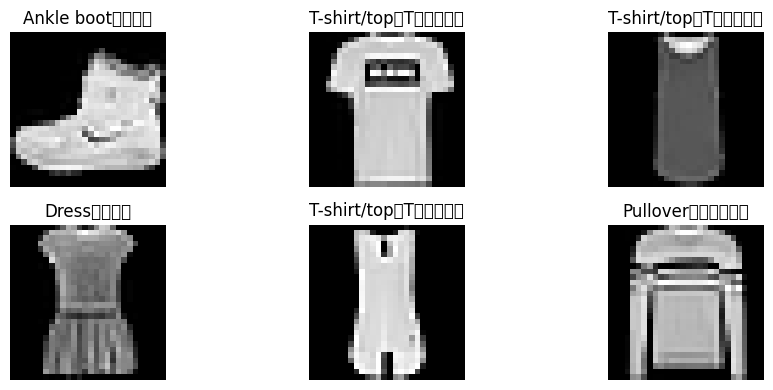

In [12]:
plt.figure(figsize=(10, 4))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [13]:
model = keras.Sequential([
    layers.Input(shape=(28, 28), name="input_image"),
    layers.Flatten(name="flatten"),
    layers.Dense(1024, activation="relu", name="dense_1024"),
    layers.BatchNormalization(name="batch_norm"),
    layers.Dropout(0.35, name="dropout_35"),
    layers.Dense(512, activation="relu", name="dense_512"),
    layers.Dropout(0.30, name="dropout_30"),
    layers.Dense(256, activation="relu", name="dense_256"),
    layers.Dropout(0.20, name="dropout_20"),
    layers.Dense(10, activation="softmax", name="output_10")
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1024 (Dense)              │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 1024)           │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10 (Dense)               │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,466,634 (5.59 MB)

 Trainable params: 1,464,586 (5.59 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [14]:
batch_size = 128
sample_batch = x_train[:batch_size]
print("批次輸入 shape：", sample_batch.shape)

for layer in model.layers:
    # 逐層傳遞資料，training=False 代表不啟用 Dropout 隨機丟棄
    sample_batch = layer(sample_batch, training=False) if isinstance(
        layer, (layers.Dropout, layers.BatchNormalization)
    ) else layer(sample_batch)
    print(layer.name, "output shape =", sample_batch.shape)


批次輸入 shape： (128, 28, 28)
flatten output shape = (128, 784)
dense_1024 output shape = (128, 1024)
batch_norm output shape = (128, 1024)
dropout_35 output shape = (128, 1024)
dense_512 output shape = (128, 512)
dropout_30 output shape = (128, 512)
dense_256 output shape = (128, 256)
dropout_20 output shape = (128, 256)
output_10 output shape = (128, 10)


In [15]:
# 編譯模型
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

epochs = 50

# 設定 callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        mode="max",
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# 開始訓練模型
history = model.fit(
    x_train,
    y_train_onehot,  # 改成 One-Hot 標籤
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.20,
    callbacks=callbacks,
    verbose=1
)

# 計算每個 epoch 的批次訓練次數
steps_per_epoch = int(np.ceil(len(x_train) * 0.8 / batch_size))

print("每個 epoch 的批次訓練次數：", steps_per_epoch)
print("實際訓練 epoch 數：", len(history.history["loss"]))

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.8004 - loss: 0.5543 - val_accuracy: 0.8413 - val_loss: 0.4555 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8454 - loss: 0.4231 - val_accuracy: 0.8368 - val_loss: 0.4357 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.8550 - loss: 0.3954 - val_accuracy: 0.8581 - val_loss: 0.3907 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8621 - loss: 0.3802 - val_accuracy: 0.8652 - val_loss: 0.3625 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8679 - loss: 0.3609 - val_accuracy: 0.8632 - val_loss: 0.3640 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8695 - loss: 0.3514 - val_accuracy: 0.8690 - val_loss: 0.3562 - learning_rate: 0.0010
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8741 - lo

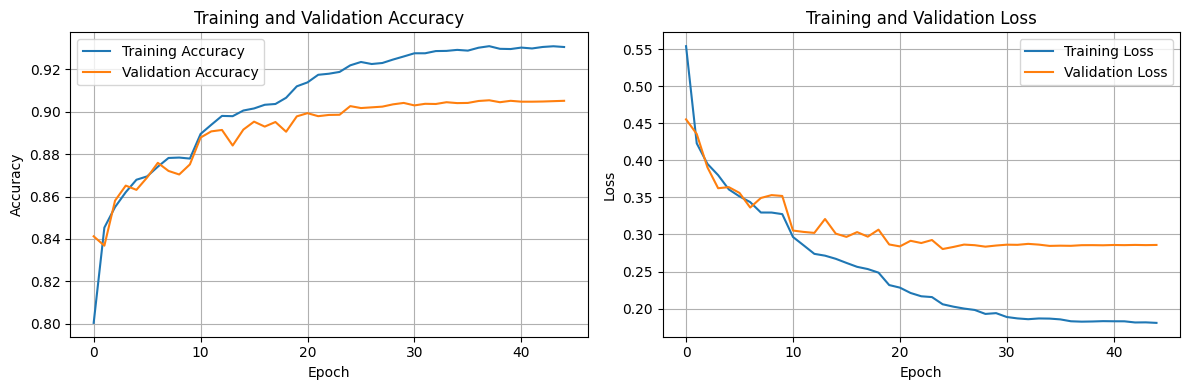

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [17]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_onehot, batch_size=batch_size, verbose=1)

print(f"測試資料 Loss：{test_loss:.4f}")
print(f"測試資料 Accuracy：{test_accuracy * 100:.2f}%")

if test_accuracy >= 0.90:
    print("已達到作業要求：測試準確率至少 90%。")
else:
    print("目前尚未達到 90%，可增加訓練 epoch、調整隱藏層神經元數或 Dropout 比例後重新訓練。")


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8997 - loss: 0.3059
測試資料 Loss：0.3059
測試資料 Accuracy：89.97%
目前尚未達到 90%，可增加訓練 epoch、調整隱藏層神經元數或 Dropout 比例後重新訓練。


In [18]:
predictions = model.predict(x_test, batch_size=batch_size, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

print("預測機率陣列 shape：", predictions.shape)
print("預測標籤 shape：", predicted_labels.shape)
print("前十筆預測標籤：", [class_names[i] for i in predicted_labels[:10]])
print("前十筆真實標籤：", [class_names[int(i)] for i in y_test[:10]])


79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
預測機率陣列 shape： (10000, 10)
預測標籤 shape： (10000,)
前十筆預測標籤： ['Ankle boot（短靴）', 'Pullover（套頭毛衣）', 'Trouser（褲子）', 'Trouser（褲子）', 'Shirt（襯衫）', 'Trouser（褲子）', 'Coat（外套）', 'Shirt（襯衫）', 'Sandal（涼鞋）', 'Sneaker（運動鞋）']
前十筆真實標籤： ['Ankle boot（短靴）', 'Pullover（套頭毛衣）', 'Trouser（褲子）', 'Trouser（褲子）', 'Shirt（襯衫）', 'Trouser（褲子）', 'Coat（外套）', 'Shirt（襯衫）', 'Sandal（涼鞋）', 'Sneaker（運動鞋）']


/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 30701 (\N{CJK UNIFIED IDEOGRAPH-77ED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_561/544083638.py:10: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) D

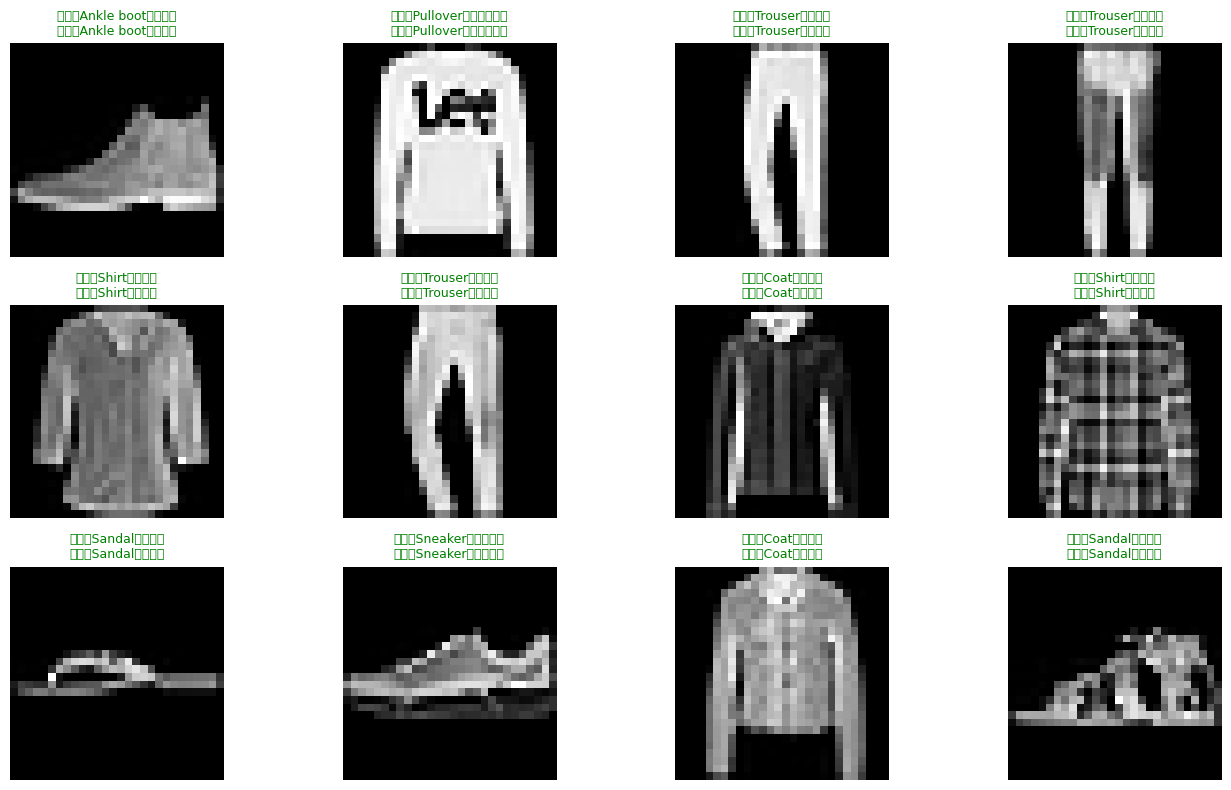

In [19]:
plt.figure(figsize=(14, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    pred_name = class_names[int(predicted_labels[i])]
    true_name = class_names[int(y_test[i])]
    color = "green" if predicted_labels[i] == y_test[i] else "red"
    plt.title(f"預測：{pred_name}\n真實：{true_name}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


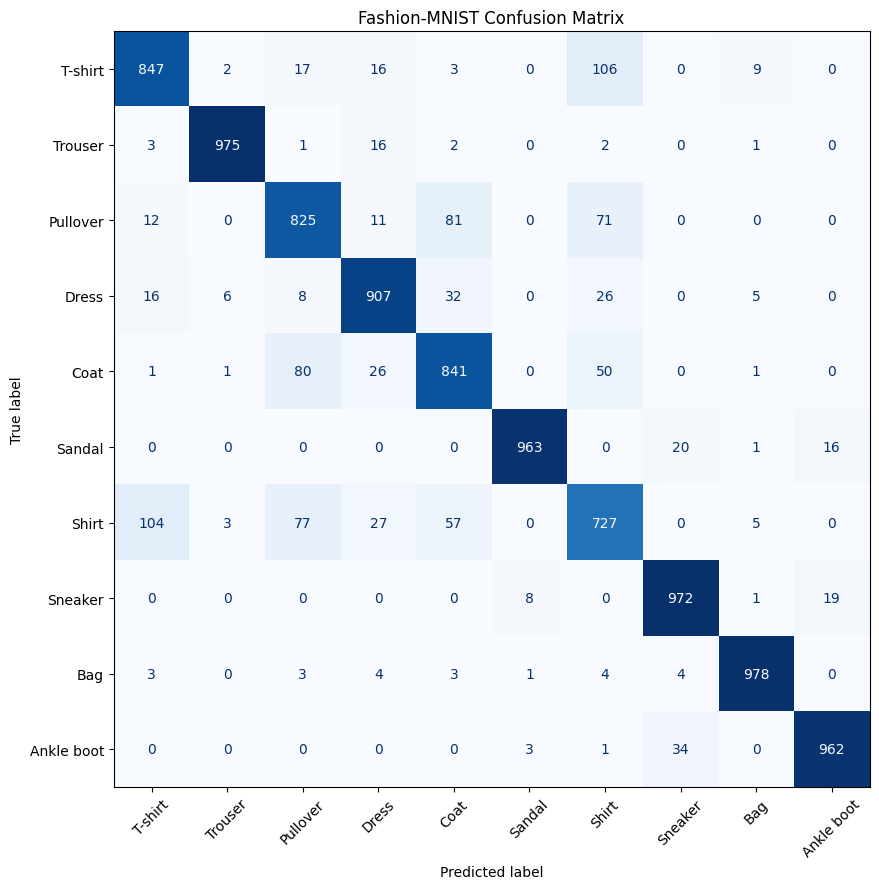

                    precision    recall  f1-score   support

T-shirt/top（T恤／上衣）     0.8590    0.8470    0.8530      1000
       Trouser（褲子）     0.9878    0.9750    0.9814      1000
    Pullover（套頭毛衣）     0.8160    0.8250    0.8205      1000
         Dress（洋裝）     0.9007    0.9070    0.9038      1000
          Coat（外套）     0.8253    0.8410    0.8331      1000
        Sandal（涼鞋）     0.9877    0.9630    0.9752      1000
         Shirt（襯衫）     0.7366    0.7270    0.7318      1000
      Sneaker（運動鞋）     0.9437    0.9720    0.9576      1000
           Bag（包包）     0.9770    0.9780    0.9775      1000
    Ankle boot（短靴）     0.9649    0.9620    0.9634      1000

          accuracy                         0.8997     10000
         macro avg     0.8999    0.8997    0.8997     10000
      weighted avg     0.8999    0.8997    0.8997     10000



In [20]:
cm = confusion_matrix(y_test, predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
])

fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(cmap="Blues", values_format="d", ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    predicted_labels,
    target_names=class_names,
    digits=4
))


In [22]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [24]:
model.save('my_dnn_model.keras')